In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [6]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

!wget $data -O homework_04_lead_scoring_2026.csv

--2026-10-11 13:52:04--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘homework_04_lead_scoring_2026.csv’

homework_04_lead_sc 100%[===================>] 272.21K  --.-KB/s    in 0.002s  

2026-10-11 13:52:04 (109 MB/s) - ‘homework_04_lead_scoring_2026.csv’ saved [278746/278746]



In [7]:
df = pd.read_csv('homework_04_lead_scoring_2026.csv')

In [8]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [9]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [10]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [11]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']#converted is the target
categorical = ['lead_source', 'industry', 'employment_status', 'location']  

In [12]:
for c in categorical:
    df[c] = df[c].fillna('NA')

    
for c in numerical:
    df[c] = df[c].fillna(0.0)

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [37]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

In [16]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

In [17]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values
y_full_train = df_full_train.converted.values

In [18]:
del df_train['converted']
del df_val['converted']
del df_test['converted']


In [19]:
for col in numerical:
  score = df_train[col]
  fpr, tpr, thresholds = roc_curve(y_train, score)
  score_auc = auc(fpr, tpr)

  # If AUC < 0.5, the feature has a negative relationship with the target
  if score_auc < 0.5:
    fpr, tpr, thresholds = roc_curve(y_train, -score)
    score_auc = auc(fpr, tpr)

  print(f"{col}: {score_auc:.3f}")

annual_income: 0.608
number_of_courses_viewed: 0.723
interaction_count: 0.765
lead_score: 0.788


In [20]:
#Answer1: lead score has the highest auc: 0.788

In [21]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [22]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.fit_transform(val_dict)
y_pred = model.predict_proba(X_val)[:, 1]

In [38]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)
AUC = auc(fpr, tpr)

In [24]:
round(AUC,3)

0.732

In [25]:
#Answer2:  auc = 0.732

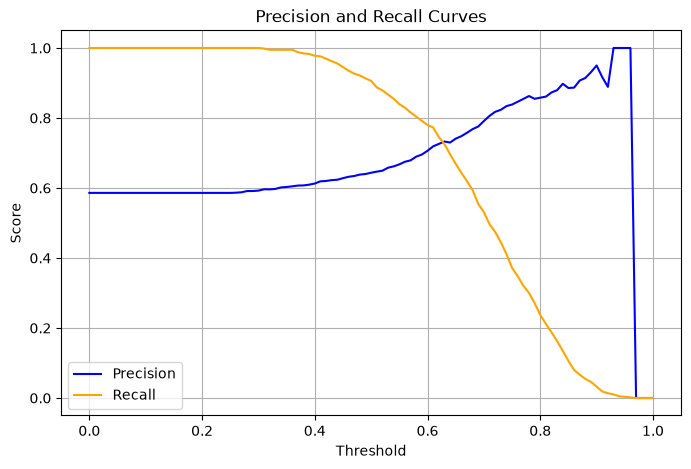

In [26]:
thresholds = np.linspace(0, 1, 101)

scores = []

for t in thresholds:
  
  y_pred_bin = (y_pred >= t).astype(int)

  # True Positives, False Positives, False Negatives
  tp = (y_pred_bin & y_val).sum()
  fp = (y_pred_bin & (1 - y_val)).sum()
  fn = ((1 - y_pred_bin) & y_val).sum()

  # precision and recall, avoiding dvide by zero
  precision = tp / (tp + fp) if (tp + fp) > 0 else 0
  recall = tp / (tp + fn) if (tp + fn) > 0 else 0

  scores.append((t, precision, recall))


df_scores = pd.DataFrame(scores, columns=["threshold", "precision", "recall"])


plt.figure(figsize=(8, 5))
plt.plot(
    df_scores["threshold"], df_scores["precision"], label="Precision", color="blue"
)
plt.plot(df_scores["threshold"], df_scores["recall"], label="Recall", color="orange")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall Curves")
plt.legend()
plt.grid(True)
plt.show()


In [27]:
# Finding the threshold where precision and recall intersect (ignoring zeros where both are 0)
valid_scores = df_scores[~((df_scores["precision"] == 0) & (df_scores["recall"] == 0))]
valid_scores = valid_scores.copy()
valid_scores["diff"] = abs(valid_scores["precision"] - valid_scores["recall"])

# Choosing the threshold with the smallest absolute difference
optimal_row = valid_scores.loc[valid_scores["diff"].idxmin()]
print(f"Optimal Threshold: {optimal_row['threshold']:.2f}")
print(
    f"Precision: {optimal_row['precision']:.3f}, Recall:"
    f" {optimal_row['recall']:.3f}"
)

Optimal Threshold: 0.63
Precision: 0.733, Recall: 0.725


In [28]:
#Answer3: 0.63

In [29]:
for t in thresholds:
 
  y_pred_bin = (y_pred >= t).astype(int)

  
  tp = (y_pred_bin & y_val).sum()
  fp = (y_pred_bin & (1 - y_val)).sum()
  fn = ((1 - y_pred_bin) & y_val).sum()

 
  precision = tp / (tp + fp) if (tp + fp) > 0 else 0
  recall = tp / (tp + fn) if (tp + fn) > 0 else 0

  # Computing F1 score
  if (precision + recall) > 0:
    f1 = (2 * precision * recall) / (precision + recall)
  else:
    f1 = 0

  scores.append((t, precision, recall, f1))


df_scores = pd.DataFrame(scores, columns=["threshold", "precision", "recall", "f1"])


In [30]:
# Finding the threshold with the maximal F1 score
optimal_f1_row = df_scores.loc[df_scores["f1"].idxmax()]

print(f"Optimal Threshold for Max F1: {optimal_f1_row['threshold']:.2f}")
print(f"Maximum F1 Score: {optimal_f1_row['f1']:.3f}")
print(
    f"Precision: {optimal_f1_row['precision']:.3f}, Recall:"
    f" {optimal_f1_row['recall']:.3f}"
)

Optimal Threshold for Max F1: 0.41
Maximum F1 Score: 0.758
Precision: 0.619, Recall: 0.976


In [31]:
#Answer4: 0.41

In [32]:
from sklearn.model_selection import KFold



In [33]:
kfold = KFold(n_splits= 5, shuffle=True, random_state=1)

In [34]:
train_idx, val_idx = next(kfold.split(df_full_train))

In [39]:
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
     df_train = df_full_train.iloc[train_idx]
     df_val = df_full_train.iloc[val_idx]

     y_train = df_train.converted.values
     y_val = df_val.converted.values

     del df_train["converted"]
     del df_val["converted"]


     dv = DictVectorizer(sparse=False)
     train_dict = df_train[categorical + numerical].to_dict(orient="records")
     X_train = dv.fit_transform(train_dict)

     val_dict = df_val[categorical + numerical].to_dict(orient="records")
     X_val = dv.transform(val_dict)

  
     model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
     model.fit(X_train, y_train)

  
     y_pred = model.predict_proba(X_val)[:, 1]
     fpr, tpr, thresholds = roc_curve(y_val, y_pred)
    
     auc_fold = auc(fpr, tpr)
     scores.append(auc_fold)

In [40]:
std_dev = np.std(scores)

In [41]:
for i, s in enumerate(scores):
  if i == 0:
    std_val = 0.0
  else:
    std_val = np.std(scores[: i +1])

  print(f"Fold {i+1}: AUC = {s:.4f} | Std (fold): {std_val:.3f}")

print(f"\nFinal Standard Deviation: {std_dev:.3f}")

Fold 1: AUC = 0.7306 | Std (fold): 0.000
Fold 2: AUC = 0.7296 | Std (fold): 0.000
Fold 3: AUC = 0.7363 | Std (fold): 0.003
Fold 4: AUC = 0.7412 | Std (fold): 0.005
Fold 5: AUC = 0.7209 | Std (fold): 0.007

Final Standard Deviation: 0.007


In [42]:
#Answer5: 0.007

In [43]:
n_splits = 5

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        del df_train["converted"]
        del df_val["converted"]


        dv = DictVectorizer(sparse=False)
        train_dict = df_train[categorical + numerical].to_dict(orient="records")
        X_train = dv.fit_transform(train_dict)

        val_dict = df_val[categorical + numerical].to_dict(orient="records")
        X_val = dv.transform(val_dict)

  
        model = LogisticRegression(solver="liblinear", C= C, max_iter=1000)
        model.fit(X_train, y_train)
        
        y_pred = model.predict_proba(X_val)[:, 1]
        fpr, tpr, thresholds = roc_curve(y_val, y_pred)
        score_auc = auc(fpr, tpr)
    
        scores.append(score_auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007


In [45]:
#Answer6: Thebest AUC is for C = 0.001